## Cell 1 — Upload and load the CSV

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

uploaded = files.upload()  # Upload Cinema_Revenue_Insight_Complete_Combined.csv
csv_file = next((name for name in uploaded if name.lower().endswith(".csv")), None)
if csv_file is None:
    raise ValueError("Please upload the combined CSV file.")

df = pd.read_csv(csv_file)
df.columns = df.columns.str.strip().str.lower()
print("Dataset:", csv_file)
print("Rows and columns:", df.shape)
display(df.head())


Saving Cinema_Revenue_Insight_Complete_Combined.csv to Cinema_Revenue_Insight_Complete_Combined.csv
Dataset: Cinema_Revenue_Insight_Complete_Combined.csv
Rows and columns: (1608, 26)


,booking_id,show_date,cinema_id,cinema,screen,movie_id,movie,show_time,seat_class,pricing_id,tickets,revenue,movie_movie,genre,language,runtime,certification,city,screen_count,screen_capacity,ticket_price,offer,discount_rate,weekday,holiday,release_week
0,B00001,2026-04-12,C004,SilverScreen Marina,C004-S5,M025,Movie 25,13:00,PREMIUM,P002,145,37700.0,Movie 25,action,Malayalam,134.0,UA,Chennai,6,200,260,No Offer,0.00,Sunday,1,0
1,B00002,2026-01-01,C002,SilverScreen North,C002-S3,M025,Movie 25,19:00,PREMIUM,P002,102,26520.0,Movie 25,action,Malayalam,134.0,UA,Coimbatore,4,150,260,No Offer,0.00,Thursday,0,1
2,B00003,2026-03-02,C005,SilverScreen City,C005-S4,M014,Movie 14,13:00,CLASSIC,P004,84,13608.0,Movie 14,sci-fi,Telugu,166.0,UA,Chennai,5,175,180,Student Offer,0.10,Monday,0,1
3,B00004,2026-03-09,C004,SilverScreen Marina,C004-S4,M026,Movie 26,19:00,PREMIUM,P005,140,33488.0,Movie 26,comedy,Tamil,106.0,U,Chennai,6,200,260,Early Bird,0.08,Monday,0,0
4,B00005,2026-03-14,C007,SilverScreen Trichy,C007-S3,M010,Movie 10,16:00,CLASSIC,P001,66,11880.0,Movie 10,comedy,Malayalam,150.0,UA,Tiruchirappalli,3,120,180,No Offer,0.00,Saturday,1,0


## Cell 2 — Dataset understanding and quality report

In [2]:
print("Column names:", df.columns.tolist())
print("\\nData types and missing values:")
quality_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(quality_report)
print("Exact duplicate rows:", df.duplicated().sum())
print("\\nNumerical summary:")
display(df.describe(include="all").T)


Column names: ['booking_id', 'show_date', 'cinema_id', 'cinema', 'screen', 'movie_id', 'movie', 'show_time', 'seat_class', 'pricing_id', 'tickets', 'revenue', 'movie_movie', 'genre', 'language', 'runtime', 'certification', 'city', 'screen_count', 'screen_capacity', 'ticket_price', 'offer', 'discount_rate', 'weekday', 'holiday', 'release_week']
\nData types and missing values:


,data_type,missing_count,missing_percent,unique_values
booking_id,object,0,0.00,1600
show_date,object,0,0.00,120
cinema_id,object,0,0.00,8
cinema,object,0,0.00,8
screen,object,0,0.00,34
movie_id,object,6,0.37,30
movie,object,0,0.00,30
show_time,object,12,0.75,5
seat_class,object,0,0.00,3
pricing_id,object,0,0.00,6


Exact duplicate rows: 8
\nNumerical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
booking_id,1608,1600,B01545,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
show_date,1608,120,2026-03-05,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cinema_id,1608,8,C006,234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cinema,1608,8,SilverScreen Madurai,234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
screen,1608,34,C008-S1,83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
movie_id,1602,30,M023,68,NaN,NaN,NaN,NaN,NaN,NaN,NaN
movie,1608,30,Movie 23,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
show_time,1596,5,19:00,525,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seat_class,1608,3,CLASSIC,943,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pricing_id,1608,6,P004,481,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Cell 3 — Data preprocessing

In [3]:
df = df.copy()

# Remove exact duplicate rows
before = len(df)
df = df.drop_duplicates()
print("Exact duplicate rows removed:", before - len(df))

# Normalize text labels
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].astype("string").str.strip()

if "genre" in df.columns:
    df["genre"] = df["genre"].str.lower().replace({
        "sci fi": "sci-fi",
        "science fiction": "sci-fi"
    })

# Convert expected numeric columns
numeric_cols = ["tickets", "revenue", "runtime", "screen_count",
                "screen_capacity", "ticket_price", "discount_rate",
                "holiday", "release_week"]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Parse date and show time
if "show_date" in df.columns:
    df["show_date"] = pd.to_datetime(df["show_date"], errors="coerce")
if "show_time" in df.columns:
    df["show_hour"] = pd.to_numeric(
        df["show_time"].astype("string").str.extract(r"^(\\d{1,2})")[0],
        errors="coerce"
    )

# Remove invalid ticket counts; missing values will be handled below
if "tickets" in df.columns:
    before = len(df)
    df = df[df["tickets"].notna() & (df["tickets"] >= 0)]
    print("Rows removed for missing/negative tickets:", before - len(df))

# Feature engineering
if "show_date" in df.columns:
    df["derived_weekday"] = df["show_date"].dt.day_name()
    df["is_weekend"] = df["show_date"].dt.dayofweek.isin([5, 6]).astype(int)

if {"tickets", "screen_capacity"}.issubset(df.columns):
    df["occupancy_rate"] = np.where(
        df["screen_capacity"] > 0,
        df["tickets"] / df["screen_capacity"],
        np.nan
    )
    # Keep occupancy only where it is physically plausible
    df.loc[(df["occupancy_rate"] < 0) | (df["occupancy_rate"] > 1), "occupancy_rate"] = np.nan
    df["occupancy_percent"] = df["occupancy_rate"] * 100

# Handle missing categorical values explicitly
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].fillna("Unknown")

print("Cleaned dataset shape:", df.shape)
print("Remaining missing values:", int(df.isna().sum().sum()))
display(df.head())


Exact duplicate rows removed: 8
Rows removed for missing/negative tickets: 5
Cleaned dataset shape: (1595, 31)
Remaining missing values: 1601


,booking_id,show_date,cinema_id,cinema,screen,movie_id,movie,show_time,seat_class,pricing_id,tickets,revenue,movie_movie,genre,language,runtime,certification,city,screen_count,screen_capacity,ticket_price,offer,discount_rate,weekday,holiday,release_week,show_hour,derived_weekday,is_weekend,occupancy_rate,occupancy_percent
0,B00001,2026-04-12,C004,SilverScreen Marina,C004-S5,M025,Movie 25,13:00,PREMIUM,P002,145,37700.0,Movie 25,action,Malayalam,134.0,UA,Chennai,6,200,260,No Offer,0.00,Sunday,1,0,<NA>,Sunday,1,0.725,72.5
1,B00002,2026-01-01,C002,SilverScreen North,C002-S3,M025,Movie 25,19:00,PREMIUM,P002,102,26520.0,Movie 25,action,Malayalam,134.0,UA,Coimbatore,4,150,260,No Offer,0.00,Thursday,0,1,<NA>,Thursday,0,0.680,68.0
2,B00003,2026-03-02,C005,SilverScreen City,C005-S4,M014,Movie 14,13:00,CLASSIC,P004,84,13608.0,Movie 14,sci-fi,Telugu,166.0,UA,Chennai,5,175,180,Student Offer,0.10,Monday,0,1,<NA>,Monday,0,0.480,48.0
3,B00004,2026-03-09,C004,SilverScreen Marina,C004-S4,M026,Movie 26,19:00,PREMIUM,P005,140,33488.0,Movie 26,comedy,Tamil,106.0,U,Chennai,6,200,260,Early Bird,0.08,Monday,0,0,<NA>,Monday,0,0.700,70.0
4,B00005,2026-03-14,C007,SilverScreen Trichy,C007-S3,M010,Movie 10,16:00,CLASSIC,P001,66,11880.0,Movie 10,comedy,Malayalam,150.0,UA,Tiruchirappalli,3,120,180,No Offer,0.00,Saturday,1,0,<NA>,Saturday,1,0.550,55.0


## Cell 4 — Outlier detection using IQR

In [4]:
outlier_rows = []
for col in ["tickets", "revenue", "ticket_price", "screen_capacity"]:
    if col not in df.columns:
        continue
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({
        "column": col, "lower_IQR_bound": lower,
        "upper_IQR_bound": upper, "outlier_count": count
    })
display(pd.DataFrame(outlier_rows))
print("Outliers are reported for review. Revenue and ticket counts are not automatically capped because extreme values may be genuine business observations.")


,column,lower_IQR_bound,upper_IQR_bound,outlier_count
0,tickets,2.0,162.0,28
1,revenue,-3915.0,38061.0,55
2,ticket_price,60.0,380.0,146
3,screen_capacity,87.5,227.5,0


Outliers are reported for review. Revenue and ticket counts are not automatically capped because extreme values may be genuine business observations.


## Cell 5 — EDA charts

,total_revenue
genre,
action,4669487.4
sci-fi,4310313.8
comedy,3778971.0
thriller,3603480.6
drama,3258480.6
romance,3204269.8
animation,3134391.8
horror,3003161.6
Unknown,89532.0


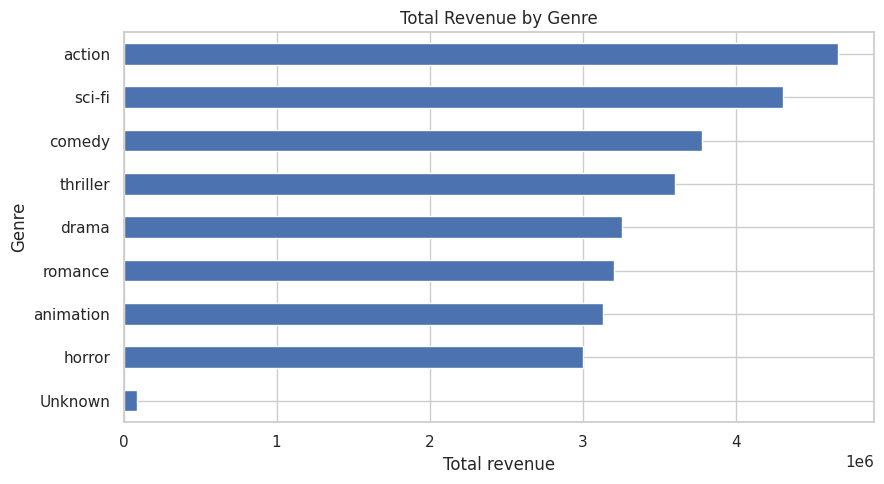

,average_occupancy_percent
show_time,
19:00,61.948948
22:00,61.259562
Unknown,53.804890
13:00,49.924050
16:00,49.840651
10:00,45.869483


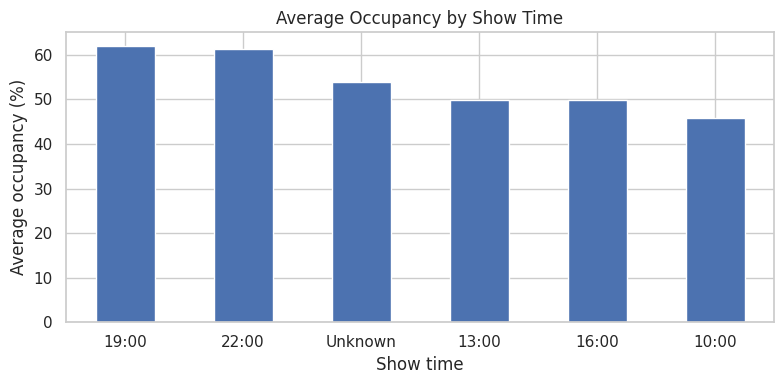

,average_tickets,total_tickets,booking_rows
is_weekend,,,
Weekday,78.653008,90215,1147
Weekend,96.732143,43336,448


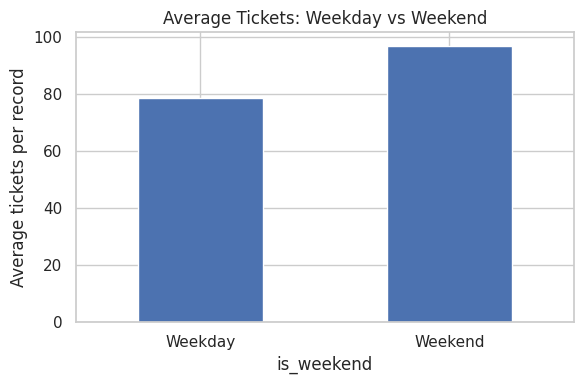

,total_revenue
cinema,
SilverScreen Marina,4612187.8
SilverScreen City,4096563.6
SilverScreen Central,4096265.2
SilverScreen Madurai,3976839.6
SilverScreen South,3565154.8
SilverScreen North,3467130.4
SilverScreen Salem,2692222.8
SilverScreen Trichy,2545724.4


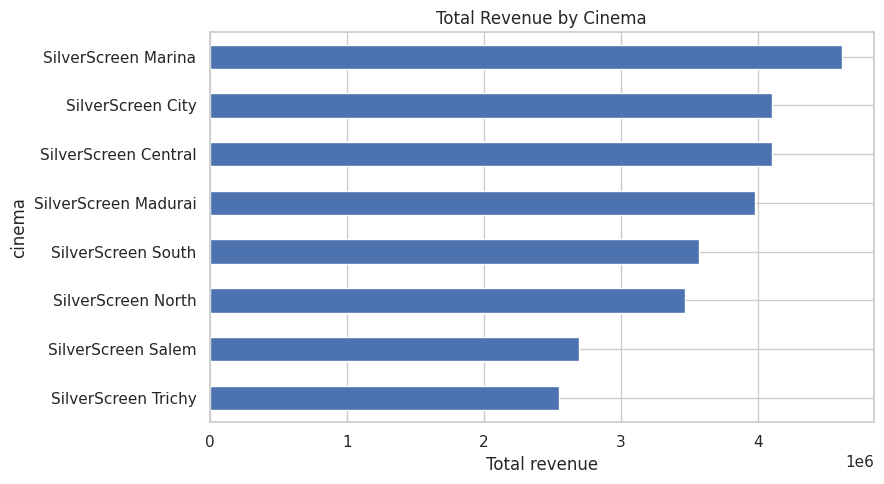

,average_tickets,total_tickets,total_revenue,records
offer,,,,
No Offer,84.232824,66207,15058300.0,786
Student Offer,84.106918,40119,6499278.0,477
Early Bird,82.335938,21078,5041857.6,256
Combo Offer,80.881579,6147,2452653.0,76


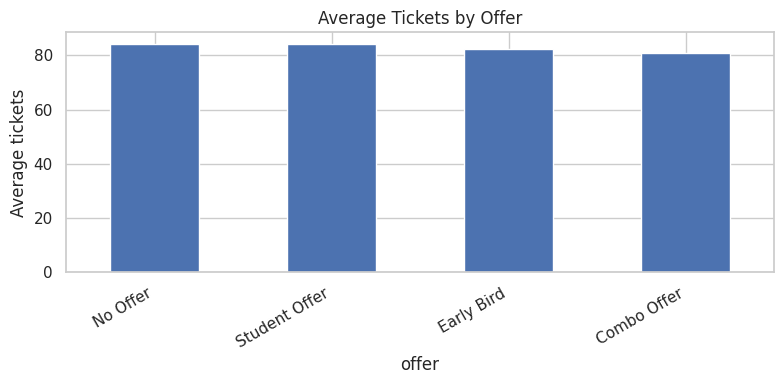

,average_tickets,total_tickets,total_revenue
release_week,,,
0,80.458559,89309,19266398.4
1,91.220619,44242,9785690.2


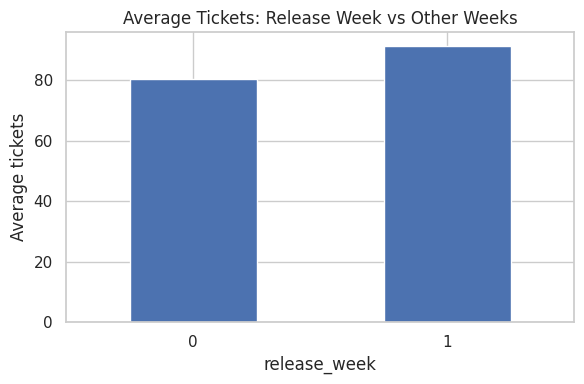

In [5]:
# 1. Total revenue by genre
if {"genre", "revenue"}.issubset(df.columns):
    genre_revenue = df.groupby("genre")["revenue"].sum().sort_values(ascending=False)
    display(genre_revenue.rename("total_revenue").to_frame())
    genre_revenue.sort_values().plot(kind="barh", figsize=(9,5), title="Total Revenue by Genre")
    plt.xlabel("Total revenue")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()

# 2. Average occupancy by show time
if {"show_time", "occupancy_percent"}.issubset(df.columns):
    show_occupancy = df.groupby("show_time")["occupancy_percent"].mean().sort_values(ascending=False)
    display(show_occupancy.rename("average_occupancy_percent").to_frame())
    show_occupancy.plot(kind="bar", figsize=(8,4), title="Average Occupancy by Show Time")
    plt.ylabel("Average occupancy (%)")
    plt.xlabel("Show time")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 3. Weekday versus weekend
if {"is_weekend", "tickets"}.issubset(df.columns):
    weekend_summary = df.groupby("is_weekend").agg(
        average_tickets=("tickets", "mean"),
        total_tickets=("tickets", "sum"),
        booking_rows=("tickets", "size")
    )
    weekend_summary.index = weekend_summary.index.map({0: "Weekday", 1: "Weekend"})
    display(weekend_summary)
    weekend_summary["average_tickets"].plot(kind="bar", figsize=(6,4), title="Average Tickets: Weekday vs Weekend")
    plt.ylabel("Average tickets per record")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 4. Revenue by cinema
if {"cinema", "revenue"}.issubset(df.columns):
    cinema_revenue = df.groupby("cinema")["revenue"].sum().sort_values(ascending=False)
    display(cinema_revenue.rename("total_revenue").to_frame())
    cinema_revenue.sort_values().plot(kind="barh", figsize=(9,5), title="Total Revenue by Cinema")
    plt.xlabel("Total revenue")
    plt.tight_layout()
    plt.show()

# 5. Offer comparison
if {"offer", "tickets", "revenue"}.issubset(df.columns):
    offer_summary = df.groupby("offer").agg(
        average_tickets=("tickets", "mean"),
        total_tickets=("tickets", "sum"),
        total_revenue=("revenue", "sum"),
        records=("booking_id", "count") if "booking_id" in df.columns else ("tickets", "count")
    ).sort_values("total_revenue", ascending=False)
    display(offer_summary)
    offer_summary["average_tickets"].plot(kind="bar", figsize=(8,4), title="Average Tickets by Offer")
    plt.ylabel("Average tickets")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# 6. Release-week comparison
if {"release_week", "tickets"}.issubset(df.columns):
    release_summary = df.groupby("release_week").agg(
        average_tickets=("tickets", "mean"),
        total_tickets=("tickets", "sum"),
        total_revenue=("revenue", "sum")
    )
    display(release_summary)
    release_summary["average_tickets"].plot(kind="bar", figsize=(6,4), title="Average Tickets: Release Week vs Other Weeks")
    plt.ylabel("Average tickets")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


## Cell 6 — Print two data-backed EDA findings

In [6]:
insights = []

if {"genre", "revenue"}.issubset(df.columns):
    s = df.groupby("genre")["revenue"].sum().sort_values(ascending=False)
    if len(s):
        insights.append(f"Highest-revenue genre is {s.index[0]} with total revenue {s.iloc[0]:,.2f}.")

if {"cinema", "revenue"}.issubset(df.columns):
    s = df.groupby("cinema")["revenue"].sum().sort_values(ascending=False)
    if len(s):
        insights.append(f"Highest-revenue cinema is {s.index[0]} with total revenue {s.iloc[0]:,.2f}.")

if {"show_time", "occupancy_percent"}.issubset(df.columns):
    s = df.groupby("show_time")["occupancy_percent"].mean().dropna().sort_values(ascending=False)
    if len(s):
        insights.append(f"Highest average occupancy occurs at {s.index[0]} ({s.iloc[0]:.2f}%).")

if {"is_weekend", "tickets"}.issubset(df.columns):
    s = df.groupby("is_weekend")["tickets"].mean()
    if 0 in s.index and 1 in s.index:
        label = "weekends" if s[1] > s[0] else "weekdays"
        insights.append(f"Average ticket count per record is higher on {label}: weekday={s[0]:.2f}, weekend={s[1]:.2f}.")

print("EDA FINDINGS")
for i, item in enumerate(insights[:4], 1):
    print(f"{i}. {item}")


EDA FINDINGS
1. Highest-revenue genre is action with total revenue 4,669,487.40.
2. Highest-revenue cinema is SilverScreen Marina with total revenue 4,612,187.80.
3. Highest average occupancy occurs at 19:00 (61.95%).
4. Average ticket count per record is higher on weekends: weekday=78.65, weekend=96.73.


## Cell 7 — Feature engineering and machine learning

In [7]:
# Regression target: number of tickets sold
target = "tickets"

# Inputs deliberately exclude revenue and occupancy to avoid target leakage
candidate_features = [
    "genre", "language", "runtime", "certification",
    "cinema", "city", "screen", "screen_count", "screen_capacity",
    "show_time", "show_hour", "seat_class", "ticket_price",
    "offer", "discount_rate", "weekday", "derived_weekday",
    "holiday", "release_week", "is_weekend"
]
features = [c for c in candidate_features if c in df.columns]

model_data = df[features + [target]].copy()
model_data[target] = pd.to_numeric(model_data[target], errors="coerce")
model_data = model_data.dropna(subset=[target])
features = [c for c in features if model_data[c].notna().any() and model_data[c].nunique(dropna=True) > 1]

if not features:
    raise ValueError("No usable features found. Check the CSV columns.")

X = model_data[features]
y = model_data[target]

categorical = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numeric = [c for c in X.columns if c not in categorical]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric),
    ("categorical", categorical_pipe, categorical)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200, random_state=42, min_samples_leaf=2, n_jobs=-1
    ))
])
model.fit(X_train, y_train)
pred = model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print("Algorithm: Random Forest Regressor")
print("Input features:", features)
print("Target variable:", target)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print(f"MAE  = {mae:.3f} tickets")
print(f"RMSE = {rmse:.3f} tickets")
print(f"R²   = {r2:.3f}")


Algorithm: Random Forest Regressor
Input features: ['genre', 'language', 'runtime', 'certification', 'cinema', 'city', 'screen', 'screen_count', 'screen_capacity', 'show_time', 'seat_class', 'ticket_price', 'offer', 'discount_rate', 'weekday', 'derived_weekday', 'holiday', 'release_week', 'is_weekend']
Target variable: tickets
Training rows: 1276 | Test rows: 319
MAE  = 17.422 tickets
RMSE = 22.363 tickets
R²   = 0.512


## Cell 8 — Model evaluation chart and feature importance

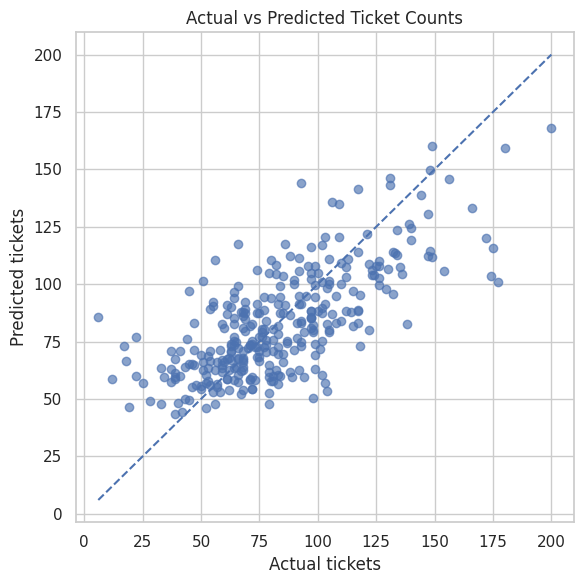

,importance
numeric__screen_capacity,0.178740
numeric__screen_count,0.175409
numeric__holiday,0.061056
categorical__show_time_19:00,0.057969
numeric__runtime,0.052353
numeric__release_week,0.034579
categorical__genre_action,0.033802
categorical__show_time_22:00,0.032993
categorical__show_time_10:00,0.021772
numeric__is_weekend,0.017865


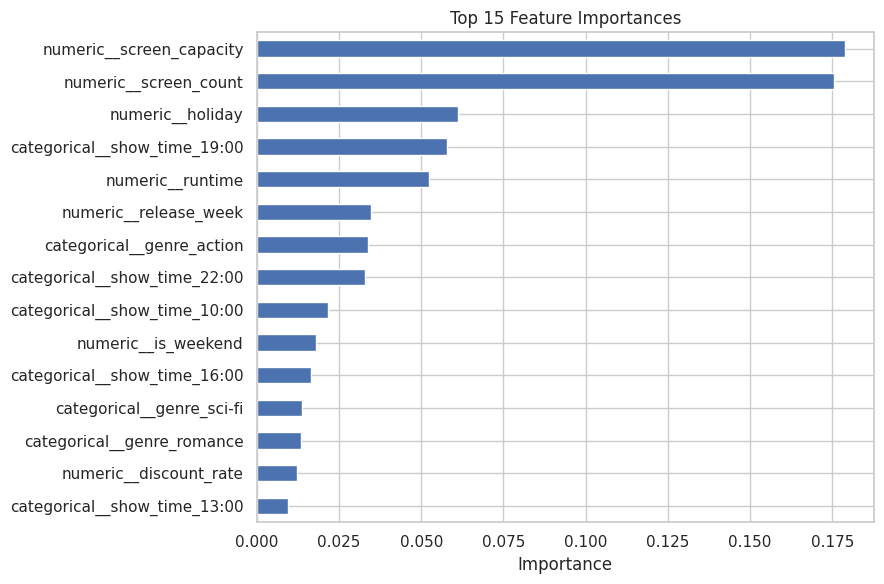

In [8]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, pred, alpha=0.65)
lo = min(float(y_test.min()), float(np.min(pred)))
hi = max(float(y_test.max()), float(np.max(pred)))
plt.plot([lo, hi], [lo, hi], linestyle="--")
plt.xlabel("Actual tickets")
plt.ylabel("Predicted tickets")
plt.title("Actual vs Predicted Ticket Counts")
plt.tight_layout()
plt.show()

try:
    names = model.named_steps["preprocessor"].get_feature_names_out()
    importances = model.named_steps["regressor"].feature_importances_
    importance = pd.Series(importances, index=names).sort_values(ascending=False).head(15)
    display(importance.rename("importance").to_frame())
    importance.sort_values().plot(kind="barh", figsize=(9,6), title="Top 15 Feature Importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
except Exception as err:
    print("Feature importance could not be displayed:", err)


## Cell 9 — Round 4 recommendations

In [9]:
recommendations = []

if {"genre", "revenue"}.issubset(df.columns):
    s = df.groupby("genre")["revenue"].sum().sort_values(ascending=False)
    if len(s):
        recommendations.append(f"Review demand and add suitable show slots for the leading revenue genre, {s.index[0]}, where local occupancy supports it.")

if {"show_time", "occupancy_percent"}.issubset(df.columns):
    s = df.groupby("show_time")["occupancy_percent"].mean().dropna().sort_values(ascending=False)
    if len(s):
        recommendations.append(f"Review capacity and scheduling around {s.index[0]}, the highest average-occupancy show time.")

if {"offer", "revenue"}.issubset(df.columns):
    s = df.groupby("offer")["revenue"].mean().sort_values(ascending=False)
    if len(s):
        recommendations.append(f"Compare offer types using net revenue and ticket volume before expanding discounts; the highest mean revenue per record is currently '{s.index[0]}'.")

if {"cinema", "revenue"}.issubset(df.columns):
    s = df.groupby("cinema")["revenue"].sum().sort_values(ascending=False)
    if len(s):
        recommendations.append(f"Benchmark lower-performing cinemas against {s.index[0]} for movie mix, show timing, capacity, and pricing.")

print("ROUND 4 — PROTOTYPE")
print("A data-analysis dashboard and Random Forest model that estimates ticket demand from movie, cinema, show-time, pricing, offer, and calendar features.")
print("\\nRECOMMENDATIONS")
for i, item in enumerate(recommendations[:4], 1):
    print(f"{i}. {item}")


ROUND 4 — PROTOTYPE
A data-analysis dashboard and Random Forest model that estimates ticket demand from movie, cinema, show-time, pricing, offer, and calendar features.
\nRECOMMENDATIONS
1. Review demand and add suitable show slots for the leading revenue genre, action, where local occupancy supports it.
2. Review capacity and scheduling around 19:00, the highest average-occupancy show time.
3. Compare offer types using net revenue and ticket volume before expanding discounts; the highest mean revenue per record is currently 'Combo Offer'.
4. Benchmark lower-performing cinemas against SilverScreen Marina for movie mix, show timing, capacity, and pricing.


## Cell 10 — Export cleaned data, predictions and metrics

In [10]:
df.to_csv("cinema_cleaned_analysis.csv", index=False)

predictions_df = X_test.copy()
predictions_df["actual_tickets"] = y_test.to_numpy()
predictions_df["predicted_tickets"] = pred
predictions_df["absolute_error"] = np.abs(predictions_df["actual_tickets"] - predictions_df["predicted_tickets"])
predictions_df.to_csv("cinema_model_predictions.csv", index=False)

metrics_df = pd.DataFrame([{
    "algorithm": "Random Forest Regressor",
    "target": target,
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2,
    "train_rows": len(X_train),
    "test_rows": len(X_test),
    "features": ", ".join(features)
}])
metrics_df.to_csv("cinema_model_metrics.csv", index=False)

display(metrics_df)
print("Saved: cinema_cleaned_analysis.csv")
print("Saved: cinema_model_predictions.csv")
print("Saved: cinema_model_metrics.csv")

# Uncomment these lines if you want to download each result immediately:
# files.download("cinema_cleaned_analysis.csv")
# files.download("cinema_model_predictions.csv")
# files.download("cinema_model_metrics.csv")


,algorithm,target,MAE,RMSE,R2,train_rows,test_rows,features
0,Random Forest Regressor,tickets,17.422239,22.363242,0.511754,1276,319,"genre, language, runtime, certification, cinem..."


Saved: cinema_cleaned_analysis.csv
Saved: cinema_model_predictions.csv
Saved: cinema_model_metrics.csv


In [11]:
import openpyxl

# Save the cleaned DataFrame to an Excel file
excel_filename = "cinema_cleaned_analysis.xlsx"
df.to_excel(excel_filename, index=False)
print(f"Saved: {excel_filename}")

# Download the file to your local computer
files.download(excel_filename)

Saved: cinema_cleaned_analysis.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>